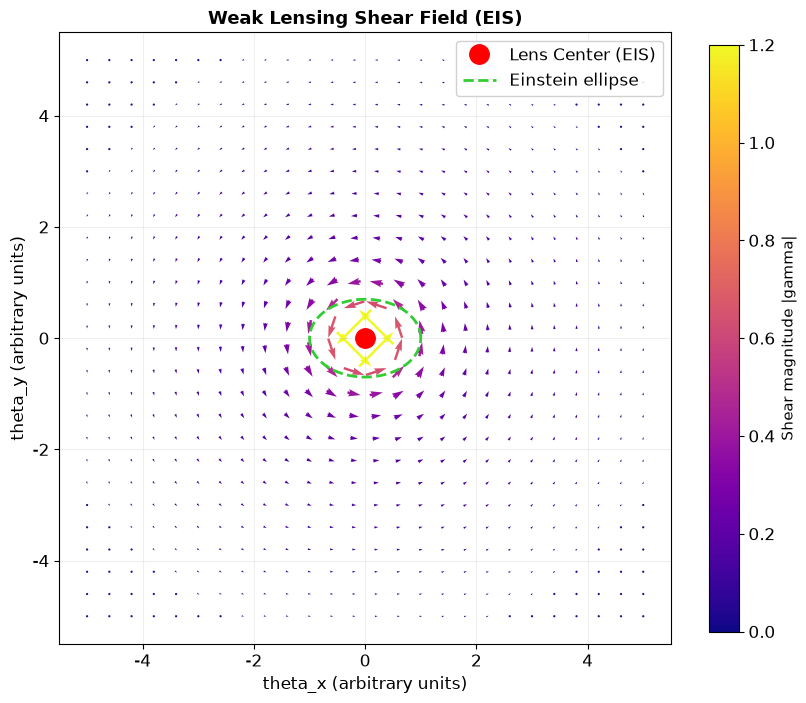

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import TwoSlopeNorm
import os

plt.rcParams['font.size'] = 12
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

os.makedirs('figures', exist_ok=True)
# 图4：EIS 透镜的弱透镜剪切场
theta_E = 1.0
e = 0.3
q = 1 - e

x = np.linspace(-5, 5, 26)
y = np.linspace(-5, 5, 26)
X, Y = np.meshgrid(x, y)

R_e = np.sqrt(X**2 + (Y / q)**2)
R_e = np.maximum(R_e, 0.35)

phi = np.arctan2(Y, X)
gamma_t = theta_E / (2 * R_e) * (1 - (e / 2) * np.cos(2 * phi))

gamma_x = -gamma_t * np.sin(phi)
gamma_y = gamma_t * np.cos(phi)

fig, ax = plt.subplots(figsize=(8.5, 7.5))

qv = ax.quiver(X, Y, gamma_x, gamma_y, gamma_t,
               cmap='plasma', scale=18, width=0.004,
               pivot='mid', clim=(0, 1.2))

ax.plot(0, 0, 'ro', ms=14, label='Lens Center (EIS)', zorder=5)

theta = np.linspace(0, 2 * np.pi, 400)
ax.plot(theta_E * np.cos(theta),
        theta_E * q * np.sin(theta),
        color='limegreen', ls='--', lw=2,
        label='Einstein ellipse')

cbar = plt.colorbar(qv, ax=ax, shrink=0.85)
cbar.set_label('Shear magnitude |gamma|', fontsize=11)

ax.set_xlabel('theta_x (arbitrary units)')
ax.set_ylabel('theta_y (arbitrary units)')
ax.set_title('Weak Lensing Shear Field (EIS)',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper right', framealpha=0.9)
ax.set_aspect('equal')
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('figures/fig4_shear_field.png', dpi=300, bbox_inches='tight')
plt.show()